# 3 · Three strategies, walk-forward, normal vs stressed periods

| | **1. Static (standard)** | **2. Dynamic (OU)** | **3. Dynamic + GARCH filter** |
|---|---|---|---|
| Hedge ratio | OLS on the previous 365 days, frozen for the next 90 days | OLS re-estimated **daily** on the previous 180 days | same as 2 |
| Pair test | Engle–Granger p < 0.05 at the start of each 90-day block, half-life 1–45 days | Engle–Granger p < 0.05 on the current 180-day window, checked at each entry | same as 2 |
| Signal | z = spread vs its formation mean, in formation s.d. | z = spread vs the fitted **Ornstein–Uhlenbeck** mean, in OU equilibrium s.d.; half-life must be 1–30 days | same as 2 |
| Entry / exit | enter at \|z\| ≥ 2; exit at z = 0; stop at \|z\| ≥ 4; close at block end | enter at \|z\| ≥ 2; exit at z = 0 (on the trade's own frozen spread); stop at \|z\| ≥ 4; **time stop after 3 OU half-lives** | same as 2, plus: **no new trades and all positions closed while the GARCH-t filter is risk-off** |

**Same data, capital and costs for all three:** 8 coins and 28 pairs (less liquid coin regressed on the more liquid one), 1 Jan 2020 – 23 May 2026. Capital is split into 8 slots of 12.5%; each open pair trade uses one slot. The same coin can appear in more than one open pair, so eight slots do not cap the exposure to one name. P&L is the marked-to-market return of the long and short positions, with units fixed at entry. It is not the change in the log-price spread. Costs are 10 bp per side per leg plus a 10%/yr fee on the short leg. A signal at the close of day *t* is filled at the close of day *t+1*. Every estimate uses only data available at that time. The weights are gross-exposure hedges: for a positive hedge ratio the net dollar weight is (1−β)/(1+β).

In [1]:
import sys, warnings
sys.path.insert(0, "../src")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from cryptopairs import plotting as P
from cryptopairs.project import setup, run_three, summary, regime_split, concurrency, START, K_SLOTS
from cryptopairs.risk import EVENTS, event_mask, high_vol_regime, var_cvar
from cryptopairs.metrics import perf
P.set_style()
pd.set_option("display.precision", 4, "display.width", 180, "display.max_columns", 30)
px, vol, mkt, sig, risk_off = setup()
res = run_three(px, vol, risk_off)
end = px.index[-1]
for n, r in res.items():
    c = concurrency(r["trades"], end)
    print(f"{n:16s} trades {len(r['trades']):3d} | max simultaneous trades {c.max()} (limit {K_SLOTS})")

Static           trades  50 | max simultaneous trades 6 (limit 8)
Dynamic          trades  76 | max simultaneous trades 6 (limit 8)
Dynamic + GARCH  trades  58 | max simultaneous trades 4 (limit 8)


## Full-period results (Jan 2020 – May 2026)

VaR and CVaR are one-day historical estimates on the portfolio's daily returns, reported as positive losses. The Sharpe ratio CI is a stationary block bootstrap (2,000 draws, mean block 20 days).

In [2]:
tab = summary(res)
tab

,net cumulative return,CAGR,ann. vol,Sharpe,max drawdown,VaR 95% (1d),CVaR 95% (1d),VaR 99% (1d),CVaR 99% (1d),trades,profitable,unsuccessful,days invested,Sharpe 95% CI
Static,-0.0436,-0.0069,0.0652,-0.0745,-0.1386,0.0039,0.008,0.0095,0.0165,50,22,28,0.442,"[-0.79, 0.55]"
Dynamic,-0.0072,-0.0011,0.0454,-0.002,-0.1266,0.0025,0.0062,0.0088,0.0131,76,41,35,0.3011,"[-0.87, 0.79]"
Dynamic + GARCH,0.0685,0.0104,0.0266,0.4028,-0.0444,0.001,0.0034,0.0046,0.0075,58,36,22,0.1914,"[-0.32, 1.09]"


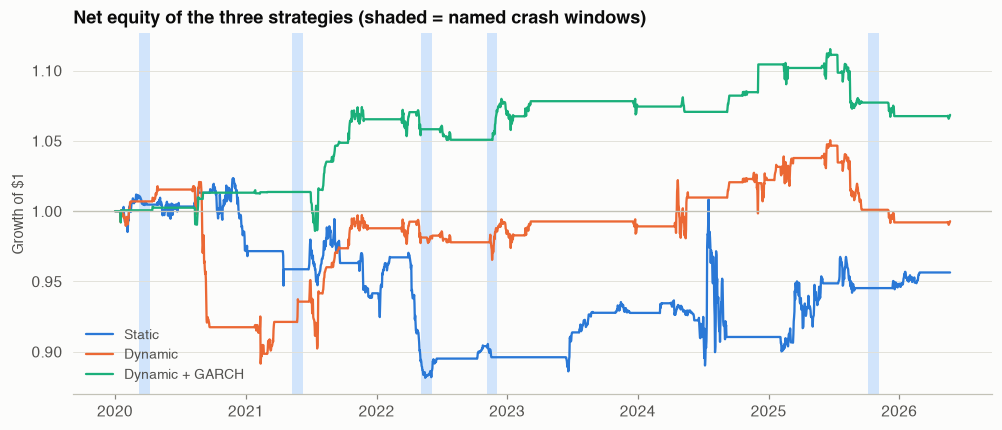

In [3]:
fig, ax = plt.subplots(figsize=(9, 3.8))
for i, (n, r) in enumerate(res.items()):
    nav = (1 + r["returns"]).cumprod()
    ax.plot(nav.index, nav, color=P.C[i], label=n, lw=1.5)
for name, (a, b) in EVENTS.items():
    ax.axvspan(pd.Timestamp(a), pd.Timestamp(b), color=P.SEQ[0], alpha=0.9, lw=0, zorder=0)
ax.axhline(1, color=P.AXIS, lw=0.9)
ax.set_ylabel("Growth of $1"); ax.set_title("Net equity of the three strategies (shaded = named crash windows)")
ax.legend(loc="lower left")
P.save(fig, "03_equity")

## Normal vs stressed periods

Two labels, both defined with hindsight and used only for reporting:

* **Named crash windows**: the five 31-day windows from notebook 1. They are not trading signals.
* **High-volatility regime**: trailing 30-day realised volatility of the mean log-return factor in the top 20% of that factor's history, the same definition as notebook 1. Before 25 June 2018 the factor uses fewer than eight coins. This label is not the GARCH trading signal.

Each strategy's daily returns are split by label and the days in each group are chained together.

In [4]:
ev = event_mask(pd.date_range(START, end))
hv = high_vol_regime(mkt)
split_ev = regime_split(res, ev, ("crash windows", "other days"))
split_hv = regime_split(res, hv, ("high volatility", "normal"))
display(split_ev)
split_hv

days  cumulative return  mean daily return (bp)  Sharpe  CVaR 95% (1d)  days invested  worst day
Static          crash windows   155.0            -0.0216                 -1.4063 -2.5937     3.2545e-03         0.4387    -0.0043
                other days     2180.0            -0.0225                 -0.0426 -0.0231     8.3348e-03         0.4422    -0.0337
Dynamic         crash windows   155.0             0.0300                  1.9249  2.0745     3.2463e-03         0.2710    -0.0075
                other days     2180.0            -0.0361                 -0.1396 -0.1105     6.3754e-03         0.3032    -0.0363
Dynamic + GARCH crash windows   155.0             0.0242                  1.5436  3.4229     3.6047e-05         0.1032    -0.0022
                other days     2180.0             0.0433                  0.2045  0.2749     3.5413e-03         0.1977    -0.0138

days  cumulative return  mean daily return (bp)  Sharpe  CVaR 95% (1d)  days invested  worst day
Static          high volatility   297.0            -0.0689                 -2.3871 -2.4177         0.0061         0.3535    -0.0168
                normal           2038.0             0.0272                  0.1953  0.1042         0.0083         0.4549    -0.0337
Dynamic         high volatility   297.0            -0.0104                 -0.2939 -0.1645         0.0095         0.4310    -0.0363
                normal           2038.0             0.0033                  0.0400  0.0349         0.0057         0.2821    -0.0199
Dynamic + GARCH high volatility   297.0            -0.0092                 -0.3045 -0.4527         0.0035         0.1650    -0.0095
                normal           2038.0             0.0785                  0.3805  0.5168         0.0034         0.1953    -0.0138

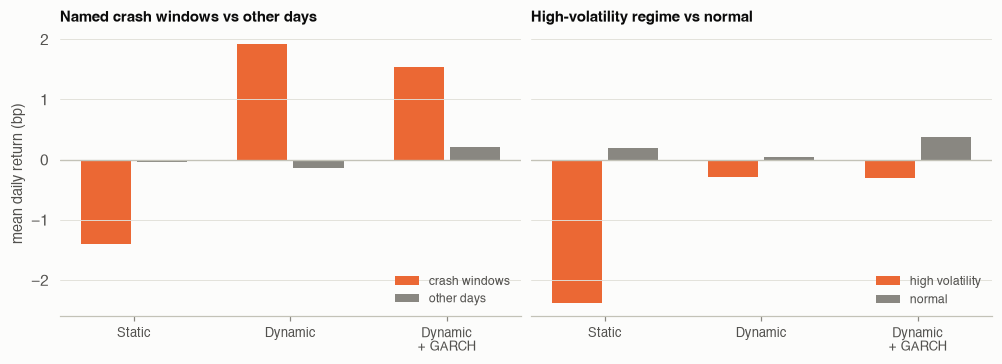

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True)
names = list(res)
for ax, (split, labs, title) in zip(axes, [(split_ev, ("crash windows", "other days"), "Named crash windows vs other days"),
                                         (split_hv, ("high volatility", "normal"), "High-volatility regime vs normal")]):
    x = np.arange(len(names)); w = 0.36
    for j, lab in enumerate(labs):
        vals = [split.loc[(n, lab), "mean daily return (bp)"] for n in names]
        ax.bar(x + (j - 0.5) * w, vals, width=w - 0.04, color=[P.C[1], P.MUTED][j], label=lab)
    ax.set_xticks(x, [n.replace(" + ", "\n+ ") for n in names], fontsize=8.5)
    ax.axhline(0, color=P.AXIS, lw=0.9); ax.set_title(title, fontsize=10)
    ax.legend(loc="lower right", fontsize=8)
axes[0].set_ylabel("mean daily return (bp)")
P.save(fig, "03_regimes")

## Trades

Profitable and unsuccessful trades, and how trades that overlapped a high-volatility period fared compared with the rest.

In [6]:
rows = []
for n, r in res.items():
    t = r["trades"].copy()
    t["stressed"] = [bool(hv.loc[a:b].any()) for a, b in zip(t.entry, t.exit)]
    for lab, g in [("all", t), ("overlapped high volatility", t[t.stressed]), ("normal only", t[~t.stressed])]:
        rows.append({"strategy": n, "trades": lab, "count": len(g), "profitable": int((g.ret > 0).sum()),
                     "unsuccessful": int((g.ret <= 0).sum()),
                     "win rate": (g.ret > 0).mean() if len(g) else np.nan,
                     "mean trade return": g.ret.mean() if len(g) else np.nan,
                     "worst trade": g.ret.min() if len(g) else np.nan,
                     "median days held": g.days.median() if len(g) else np.nan})
trades_tab = pd.DataFrame(rows).set_index(["strategy", "trades"])
trades_tab

count  profitable  unsuccessful  win rate  mean trade return  worst trade  median days held
strategy        trades                                                                                                                 
Static          all                            50          22            28    0.4400            -0.0079      -0.2167              25.5
                overlapped high volatility      8           3             5    0.3750            -0.0265      -0.1807              53.0
                normal only                    42          19            23    0.4524            -0.0043      -0.2167              21.0
Dynamic         all                            76          41            35    0.5395            -0.0011      -0.2073              14.0
                overlapped high volatility     20          15             5    0.7500             0.0249      -0.1634              16.0
                normal only                    56          26            30    0.4643            -0.0105      -0.2073              13.0
Dynamic + GARCH all                            58          36            22    0.6207             0.0091      -0.1349              10.0
                overlapped high volatility     14          10             4    0.7143             0.0225      -0.0836              10.5
                normal only                    44          26            18    0.5909             0.0048      -0.1349              10.0

In [7]:
exits = pd.DataFrame({n: r["trades"].reason.value_counts(normalize=True) for n, r in res.items()}).fillna(0)
exits.index.name = "exit reason (share of trades)"
exits

,Static,Dynamic,Dynamic + GARCH
exit reason (share of trades),,,
revert,0.20,0.1053,0.0862
risk_off,0.00,0.0000,0.2931
stop,0.32,0.2500,0.1379
time_stop,0.00,0.6316,0.4655
window_end,0.48,0.0132,0.0172


## Reading the results

* **Read the table above; the intervals contain zero.** With the liquidity ranking frozen on 31 December 2019, the static book returns −4.4% (Sharpe −0.07), the dynamic book −0.7% (0.00) and the filtered book +6.8% (0.40). Each block-bootstrap interval contains zero. The +6.8% is not established as a positive edge.
* **The positions are gross-exposure hedges, not dollar-neutral.** For a positive hedge ratio the net dollar weight is (1 − β) / (1 + β). At the median lagged ratio near 0.69 that is about 18% net long. Eight slots do not stop the same coin appearing in several pairs.
* **The filtered book is invested less often.** Part of its smaller drawdown is time in cash. A bootstrap of each Sharpe ratio on its own does not test the difference between the dynamic book and the filtered book.
* **Exit reasons are in the table above.** Wins and losses are close in count, so the result depends on the size of the losing trades, which is what the stops, the time stop and the filter change.